# Interpretabilidad del modelo final (SHAP) y análisis de sesgos y limitaciones

Semana 13 del plan de trabajo (`proposal.md`, sección 13).

En el notebook `05_evaluacion_final.ipynb` se evaluó el modelo ganador (**L: LightGBM final**, entrenado con enero-mayo al 50 % y evaluado una sola vez sobre junio), obteniendo **MAE = 3.694 min** y **RMSLE = 0.3066**, además del desglose de error por hora, zona y distancia.

Este notebook completa la etapa de análisis e interpretabilidad:

1. **Importancia nativa de LightGBM (*Gain* y *Split*):** qué variables aportan mayor reducción de pérdida frente a cuáles se usan más veces para particionar nodos.
2. **Interpretabilidad global con SHAP (`TreeExplainer`):** magnitud y dirección del impacto de cada feature sobre la predicción $\log(1 + \text{duración})$ en una muestra representativa de junio (`N = 10,000`).
3. **Interacciones y explicaciones locales (*Dependence* y *Waterfall*):** cómo interactúan distancia, hora y fin de semana, y por qué el modelo acierta con precisión en viajes típicos de Manhattan pero subestima casos extremos en aeropuertos (JFK).
4. **Discusión formal de sesgos, limitaciones y riesgos éticos** del sistema de predicción.


In [1]:
import sys
sys.path.append('..')

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_log_error

try:
    import shap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'shap>=0.45'])
    import shap

import src.features as features
features.RUTA_ZONAS = Path('../data/Taxi_Zone_Lookup.csv')

from src.data import cargar_todo, MESES
from src.features import construir_preprocesador, preparar_xy

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120

Path('../reports/figures').mkdir(parents=True, exist_ok=True)
Path('../outputs').mkdir(parents=True, exist_ok=True)
print(f'LightGBM: {lgb.__version__} | SHAP: {shap.__version__}')


LightGBM: 4.7.0 | SHAP: 0.54.1


## 1. Reconstrucción del modelo final (enero-mayo $\to$ junio)

Se carga exactamente la configuración congelada en `outputs/config_modelo_final.json` y se ajusta el preprocesador únicamente sobre enero-mayo (`SAMPLE_FRAC = 0.5`, `SEED = 42`), verificando que las métricas en junio coincidan con `outputs/metrics_evaluacion_final.json`.


In [2]:
with open('../outputs/config_modelo_final.json', encoding='utf-8') as f:
    config = json.load(f)

SAMPLE_FRAC = config.get('sample_frac', 0.5)
df = cargar_todo(meses=MESES, sample_frac=SAMPLE_FRAC, seed=SEED)

mes_num = df['tpep_pickup_datetime'].dt.month
train_final = df[mes_num.between(1, 5)].copy()
test = df[mes_num == 6].copy()
del df
gc.collect()

X_tr, y_tr = preparar_xy(train_final, target_col='trip_duration_min', usar_log_target=True)
X_te, _ = preparar_xy(test, target_col='trip_duration_min', usar_log_target=True)
y_te = test['trip_duration_min'].to_numpy(dtype=float)

preprocesador = construir_preprocesador(escalar_numericas=False)
X_tr_proc = preprocesador.fit_transform(X_tr, y_tr).astype(np.float32)
X_te_proc = preprocesador.transform(X_te).astype(np.float32)

del train_final, X_tr
gc.collect()

modelo_final = lgb.LGBMRegressor(
    **config['params'],
    **config['params_fijos'],
    n_estimators=config['n_estimators'],
)
modelo_final.fit(X_tr_proc, y_tr)
del X_tr_proc, y_tr
gc.collect()

pred_log = modelo_final.predict(X_te_proc)
pred_min = np.clip(np.expm1(pred_log), 0, None)

mae_test = mean_absolute_error(y_te, pred_min)
rmsle_test = np.sqrt(mean_squared_log_error(y_te, pred_min))
print(f'Verificación en junio -> MAE: {mae_test:.4f} min | RMSLE: {rmsle_test:.4f}')

test = test.copy()
test['pred_min'] = pred_min
test['error_abs'] = np.abs(test['trip_duration_min'] - test['pred_min'])
test['error_sesgo'] = test['pred_min'] - test['trip_duration_min']
test['pickup_hour'] = test['tpep_pickup_datetime'].dt.hour  # usada para elegir los casos locales (sección 4.2)


C:\Users\joacm\Documents\UTEC\26-2\Machine Learning\proy-machine\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Verificación en junio -> MAE: 3.6952 min | RMSLE: 0.3067


In [3]:
raw_feature_names = list(preprocesador.named_steps['codificador'].get_feature_names_out())

def limpiar_nombre_feature(nombre: str) -> str:
    if nombre.startswith('num__'):
        return nombre.replace('num__', '')
    if nombre.startswith('target_enc__'):
        return nombre.replace('target_enc__', '') + ' (TargetEnc)'
    if nombre.startswith('onehot__'):
        return nombre.replace('onehot__', '')
    return nombre

nombres_features = [limpiar_nombre_feature(n) for n in raw_feature_names]
print(f'Total de features transformadas: {len(nombres_features)}')


Total de features transformadas: 41


## 2. Importancia nativa de LightGBM (*Gain* vs. *Split*)

En árboles de decisión con gradient boosting existen dos criterios complementarios para medir importancia:
- **Gain (ganancia total):** suma de la reducción en la función de pérdida (`L1` sobre `log1p`) atribuida a cada variable. Mide **cuánto mejora la precisión** del modelo.
- **Split (frecuencia de corte):** número de veces que una variable es elegida para dividir un nodo a lo largo de los `1,710` árboles. Tiende a favorecer variables continuas o de alta granularidad.


,feature,gain_pct,split,split_pct
0,distancia_estimada_mi,52.50,96042,20.06
1,log_distancia_estimada,22.34,30483,6.37
2,DOLocationID (TargetEnc),5.33,80222,16.75
3,PULocationID (TargetEnc),5.13,82627,17.26
4,pickup_hour,3.96,44203,9.23
5,hora_cos,1.98,20308,4.24
6,hora_sin,1.19,20964,4.38
7,pickup_dayofweek,1.18,23576,4.92
8,pickup_month,0.95,21042,4.39
9,dia_sin,0.88,16119,3.37


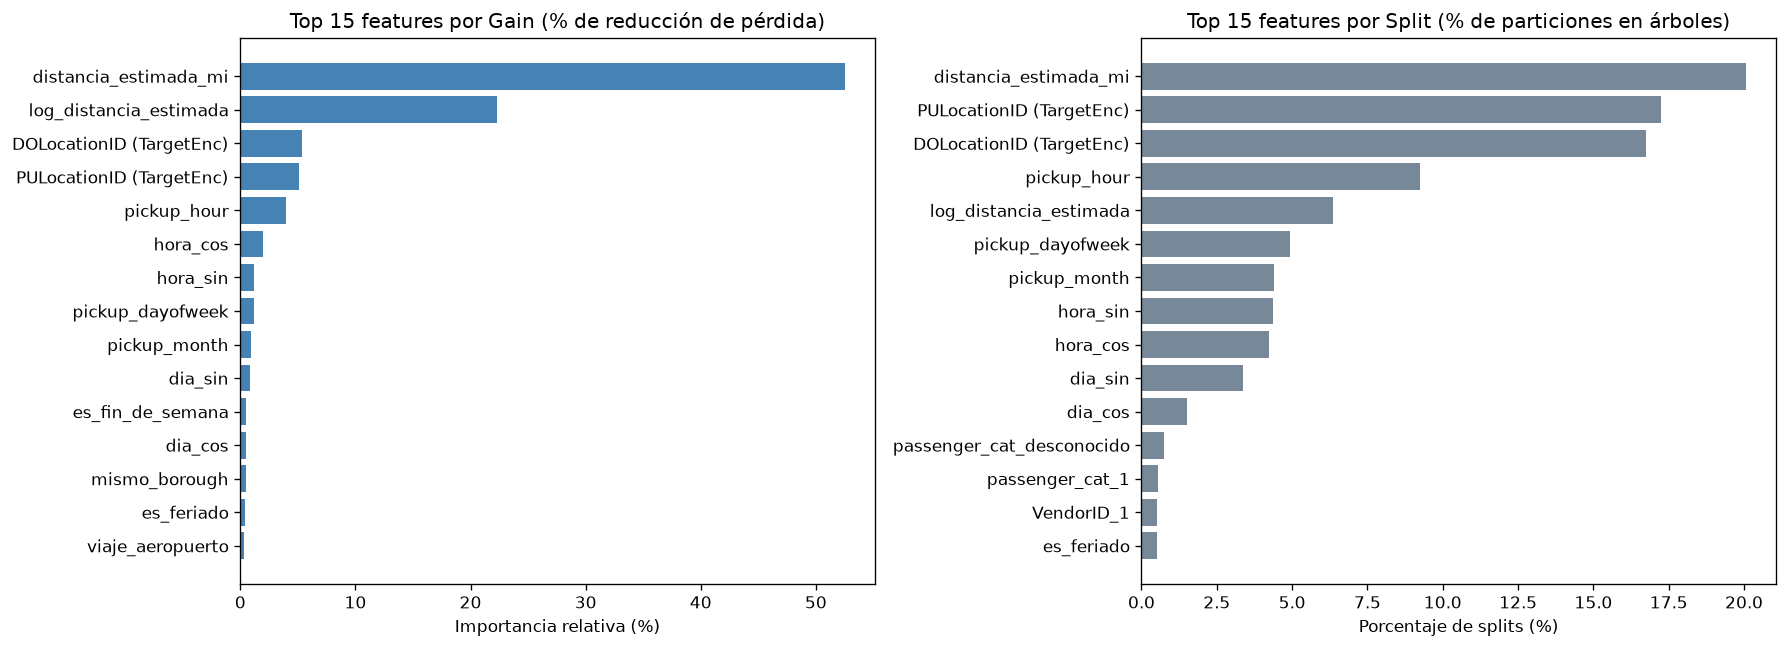

In [4]:
booster = modelo_final.booster_
imp_gain = booster.feature_importance(importance_type='gain')
imp_split = booster.feature_importance(importance_type='split')

df_importancia = pd.DataFrame({
    'feature_raw': raw_feature_names,
    'feature': nombres_features,
    'gain': imp_gain,
    'gain_pct': 100 * imp_gain / imp_gain.sum(),
    'split': imp_split,
    'split_pct': 100 * imp_split / imp_split.sum(),
}).sort_values('gain', ascending=False).reset_index(drop=True)

display(df_importancia.head(15)[['feature', 'gain_pct', 'split', 'split_pct']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

top_gain = df_importancia.head(15).iloc[::-1]
axes[0].barh(top_gain['feature'], top_gain['gain_pct'], color='steelblue')
axes[0].set_title('Top 15 features por Gain (% de reducción de pérdida)')
axes[0].set_xlabel('Importancia relativa (%)')

top_split = df_importancia.sort_values('split', ascending=False).head(15).iloc[::-1]
axes[1].barh(top_split['feature'], top_split['split_pct'], color='lightslategray')
axes[1].set_title('Top 15 features por Split (% de particiones en árboles)')
axes[1].set_xlabel('Porcentaje de splits (%)')

plt.tight_layout()
plt.savefig('../reports/figures/11_importancia_features.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Interpretabilidad global con valores SHAP (`TreeExplainer`)

A diferencia de *Gain* o *Split*, los **valores SHAP** (Shapley Additive exPlanations) descomponen cada predicción individual como:

$$\hat{y}_i = \phi_0 + \sum_{j=1}^{41} \phi_{i,j}$$

donde $\phi_0$ es la predicción base promedio en escala $\log(1 + \text{duración})$ y $\phi_{i,j}$ es la contribución exacta (positiva o negativa) de la feature $j$ en el viaje $i$.

Se calcula `TreeExplainer` sobre una muestra aleatoria reproducible de **10,000 viajes de junio** (`SEED = 42`).


Valor base esperado (E[log1p(duración)]): 2.6280 (~12.85 min)


,feature,mean_abs_shap,mean_abs_shap_pct
0,distancia_estimada_mi,0.3205,35.1588
1,log_distancia_estimada,0.1273,13.9657
2,hora_cos,0.0603,6.6208
3,pickup_hour,0.0592,6.4911
4,PULocationID (TargetEnc),0.0503,5.5220
5,pickup_month,0.0496,5.4425
6,DOLocationID (TargetEnc),0.0484,5.3152
7,hora_sin,0.0217,2.3808
8,dia_sin,0.0204,2.2373
9,pickup_dayofweek,0.0164,1.7968


C:\Users\joacm\AppData\Local\Temp\ipykernel_25224\8411198.py:26: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


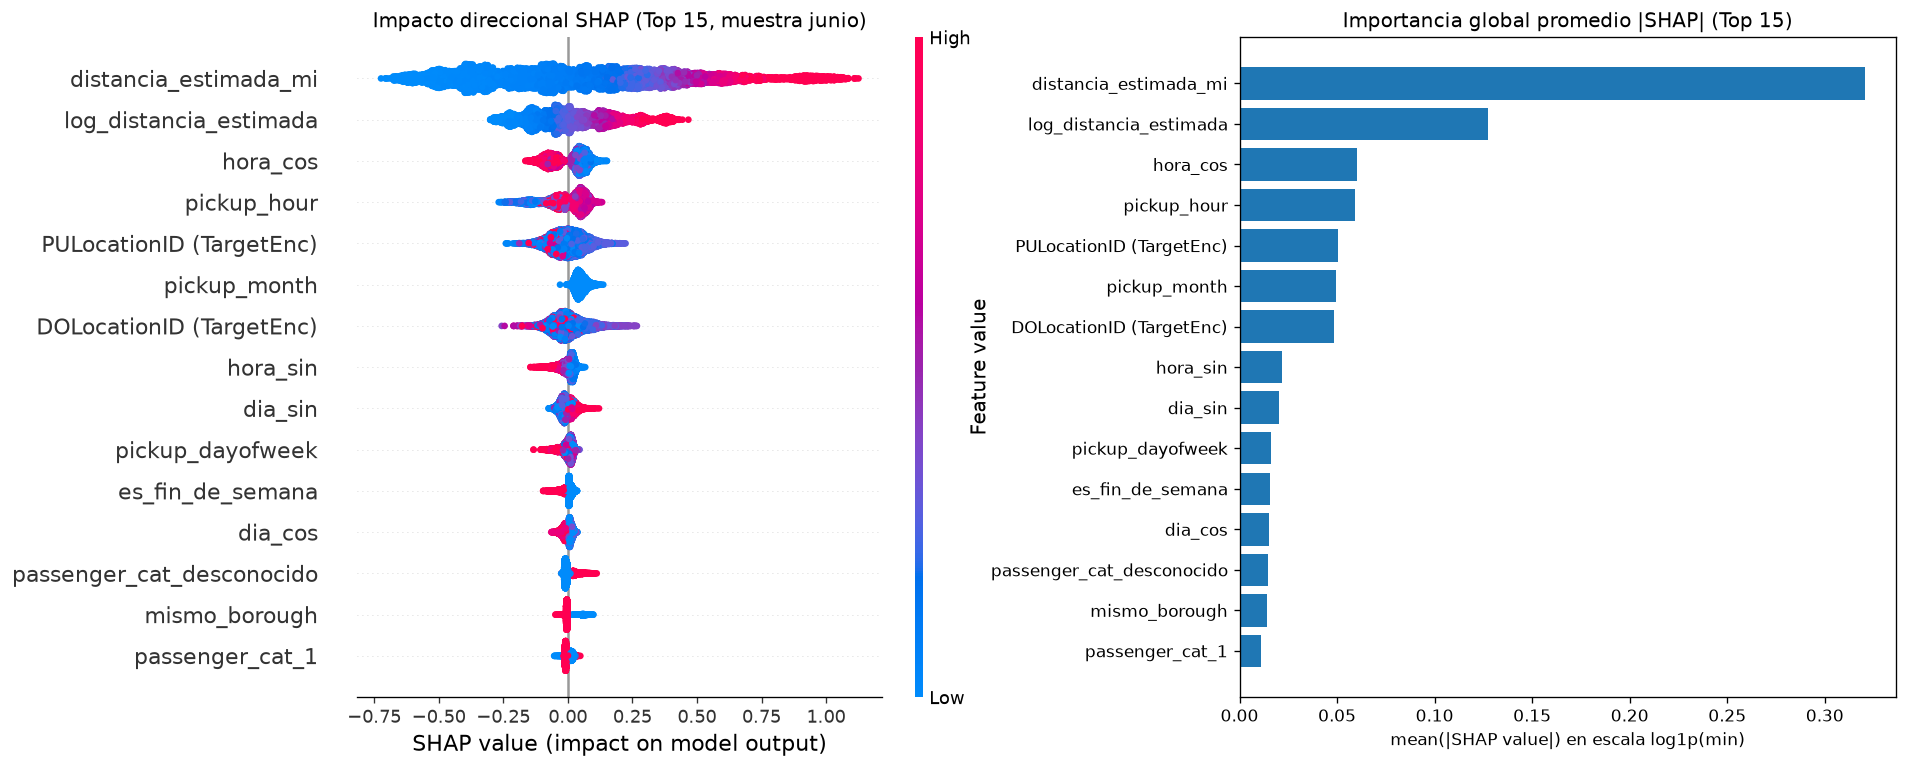

In [5]:
N_SHAP = 10_000
rng = np.random.default_rng(SEED)
idx_shap = np.sort(rng.choice(len(test), size=N_SHAP, replace=False))

X_shap = X_te_proc[idx_shap]
df_shap_meta = test.iloc[idx_shap].reset_index(drop=True)

explainer = shap.TreeExplainer(modelo_final)
shap_values = explainer.shap_values(X_shap)
base_value = float(np.atleast_1d(explainer.expected_value)[0])

mean_abs_shap = np.abs(shap_values).mean(axis=0)
df_shap_imp = pd.DataFrame({
    'feature_raw': raw_feature_names,
    'feature': nombres_features,
    'mean_abs_shap': mean_abs_shap,
    'mean_abs_shap_pct': 100 * mean_abs_shap / mean_abs_shap.sum(),
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

print(f'Valor base esperado (E[log1p(duración)]): {base_value:.4f} (~{np.expm1(base_value):.2f} min)')
display(df_shap_imp.head(15)[['feature', 'mean_abs_shap', 'mean_abs_shap_pct']].round(4))

fig = plt.figure(figsize=(16, 6.5))

ax1 = fig.add_subplot(1, 2, 1)
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=nombres_features,
    max_display=15,
    show=False,
    plot_size=None,
)
plt.title('Impacto direccional SHAP (Top 15, muestra junio)')

ax2 = fig.add_subplot(1, 2, 2)
top_s = df_shap_imp.head(15).iloc[::-1]
ax2.barh(top_s['feature'], top_s['mean_abs_shap'], color='#1f77b4')
ax2.set_xlabel('mean(|SHAP value|) en escala log1p(min)')
ax2.set_title('Importancia global promedio |SHAP| (Top 15)')

plt.tight_layout()
plt.savefig('../reports/figures/12_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Interacciones no lineales y explicaciones locales (*Waterfall*)

### 4.1 Dependencia SHAP e interacciones
Analizamos cómo varía la contribución SHAP de las dos variables dominantes según el contexto del viaje:
1. **`log_distancia_estimada` coloreada por `pickup_hour`:** muestra si una misma distancia histórica penaliza más la duración en horas diurnas congestionadas que de madrugada.
2. **`pickup_hour` coloreada por `es_fin_de_semana`:** muestra cómo el modelo captura la diferencia entre la congestión laboral diurna (lunes a viernes) y el patrón nocturno/tardío de fin de semana.


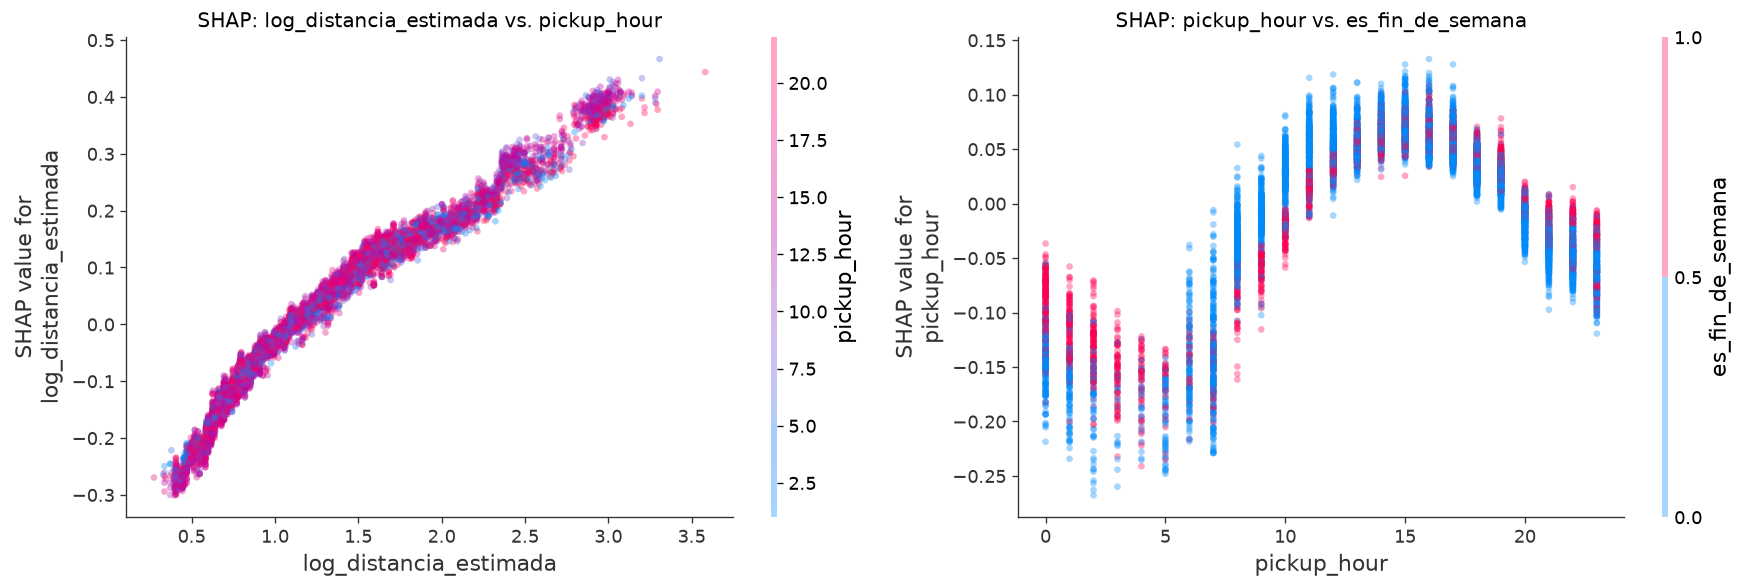

In [6]:
idx_log_dist = nombres_features.index('log_distancia_estimada')
idx_hour = nombres_features.index('pickup_hour')
idx_wknd = nombres_features.index('es_fin_de_semana')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

shap.dependence_plot(
    idx_log_dist,
    shap_values,
    X_shap,
    feature_names=nombres_features,
    interaction_index=idx_hour,
    ax=axes[0],
    show=False,
    alpha=0.35,
)
axes[0].set_title('SHAP: log_distancia_estimada vs. pickup_hour')

shap.dependence_plot(
    idx_hour,
    shap_values,
    X_shap,
    feature_names=nombres_features,
    interaction_index=idx_wknd,
    ax=axes[1],
    show=False,
    alpha=0.35,
)
axes[1].set_title('SHAP: pickup_hour vs. es_fin_de_semana')

plt.tight_layout()
plt.savefig('../reports/figures/13_shap_dependencia.png', dpi=150, bbox_inches='tight')
plt.show()


### 4.2 Explicaciones locales: 3 arquetipos de viaje en junio

Inspeccionamos la descomposición SHAP individual (*Waterfall*) de tres casos concretos dentro de la muestra de junio:
1. **Caso A (Alta precisión — Manhattan madrugada):** viaje corto de madrugada en Manhattan donde el modelo acierta casi al segundo.
2. **Caso B (Hora punta laboral):** viaje diurno en día hábil donde las variables temporales y de zona empujan la predicción al alza.
3. **Caso C (Subestimación extrema — Aeropuerto JFK):** viaje con origen/destino en JFK (`LocationID = 132`) con error absoluto alto, ilustrando qué ocurre cuando un evento atípico de tráfico supera la mediana histórica de la ruta.


Caso A: Madrugada Manhattan (bajo error)
  Ruta: Meatpacking/West Village West -> Greenwich Village South | Hora: 3h | Real: 9.0 min | Pred: 8.5 min



Caso B: Hora punta laboral (tarde)
  Ruta: Manhattan Valley -> Upper West Side North | Hora: 15h | Real: 5.5 min | Pred: 6.3 min



Caso C: Aeropuerto JFK (subestimación atípica)
  Ruta: JFK Airport -> Times Sq/Theatre District | Hora: 22h | Real: 67.8 min | Pred: 43.4 min



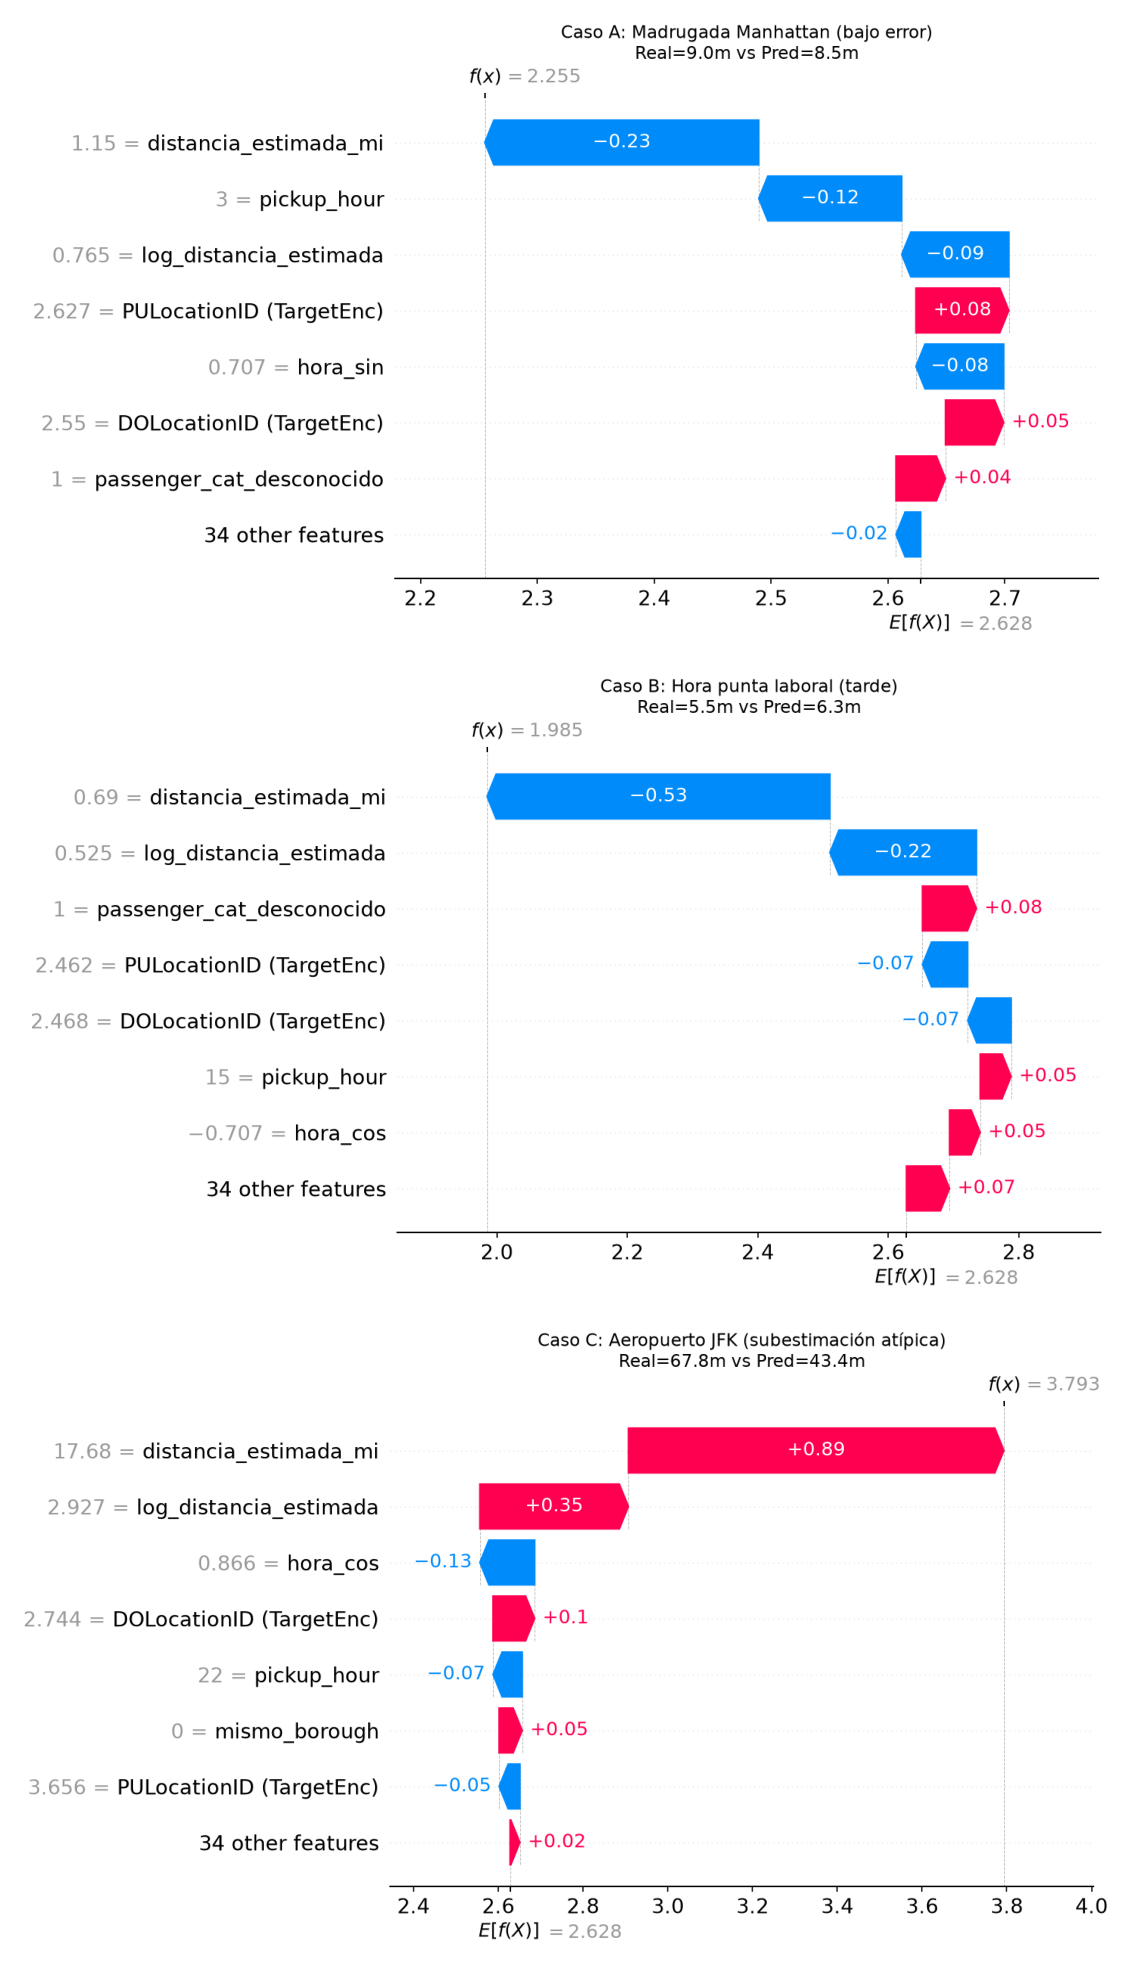

In [7]:
zonas_df = pd.read_csv('../data/Taxi_Zone_Lookup.csv').set_index('LocationID')

cond_A = (
    (df_shap_meta['pickup_hour'].between(2, 4))
    & (~df_shap_meta['PULocationID'].isin([1, 132, 138]))
    & (df_shap_meta['error_abs'] < 0.5)
)
cond_B = (
    (df_shap_meta['pickup_hour'].between(15, 17))
    & (df_shap_meta['tpep_pickup_datetime'].dt.dayofweek < 5)
    & (df_shap_meta['error_abs'] < 1.5)
)
cond_C = (
    ((df_shap_meta['PULocationID'] == 132) | (df_shap_meta['DOLocationID'] == 132))
    & (df_shap_meta['trip_duration_min'] - df_shap_meta['pred_min'] > 15.0)
)

casos = [
    ('Caso A: Madrugada Manhattan (bajo error)', int(df_shap_meta[cond_A].index[0])),
    ('Caso B: Hora punta laboral (tarde)', int(df_shap_meta[cond_B].index[0])),
    ('Caso C: Aeropuerto JFK (subestimación atípica)', int(df_shap_meta[cond_C].index[0])),
]

# shap.plots.waterfall redimensiona la figura activa, así que cada caso se dibuja
# en su propia figura y después se apilan las tres imágenes en una sola.
from io import BytesIO

imagenes = []
for titulo, pos in casos:
    fila = df_shap_meta.iloc[pos]
    pu_nom = zonas_df.loc[fila['PULocationID'], 'Zone'] if fila['PULocationID'] in zonas_df.index else str(fila['PULocationID'])
    do_nom = zonas_df.loc[fila['DOLocationID'], 'Zone'] if fila['DOLocationID'] in zonas_df.index else str(fila['DOLocationID'])
    print(
        f'{titulo}\n'
        f'  Ruta: {pu_nom} -> {do_nom} | Hora: {int(fila["pickup_hour"])}h | '
        f'Real: {fila["trip_duration_min"]:.1f} min | Pred: {fila["pred_min"]:.1f} min\n'
    )

    exp = shap.Explanation(
        values=shap_values[pos],
        base_values=base_value,
        data=np.round(X_shap[pos], 3),
        feature_names=nombres_features,
    )
    plt.figure()
    shap.plots.waterfall(exp, max_display=8, show=False)
    plt.title(f'{titulo}\nReal={fila["trip_duration_min"]:.1f}m vs Pred={fila["pred_min"]:.1f}m', fontsize=11)
    buf = BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight')
    plt.close()
    buf.seek(0)
    imagenes.append(plt.imread(buf))

fig, axes = plt.subplots(len(imagenes), 1, figsize=(10, 5.5 * len(imagenes)))
for ax, img in zip(axes, imagenes):
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.savefig('../reports/figures/14_shap_casos_locales.png', dpi=150, bbox_inches='tight')
plt.show()


In [8]:
resumen_shap = {
    'modelo': config['modelo'],
    'n_muestra_shap': N_SHAP,
    'seed': SEED,
    'expected_value_log1p': round(base_value, 6),
    'expected_value_min': round(float(np.expm1(base_value)), 3),
    'top_10_gain': (
        df_importancia.head(10)[['feature', 'gain_pct', 'split_pct']]
        .round(3)
        .to_dict(orient='records')
    ),
    'top_10_shap': (
        df_shap_imp.head(10)[['feature', 'mean_abs_shap', 'mean_abs_shap_pct']]
        .round(4)
        .to_dict(orient='records')
    ),
}

with open('../outputs/interpretabilidad_shap.json', 'w', encoding='utf-8') as f:
    json.dump(resumen_shap, f, indent=2, ensure_ascii=False)

print('Guardado en ../outputs/interpretabilidad_shap.json')


Guardado en ../outputs/interpretabilidad_shap.json


## 5. Lectura de interpretabilidad, sesgos y limitaciones

### 5.1 Qué aprendió realmente el modelo (síntesis Gain + SHAP)

*Nota de reproducibilidad:* el modelo reconstruido da MAE = 3.695 min en junio, contra 3.694 en el notebook 05. La diferencia de 0.001 min viene de entrenar con las features en `float32` (aquí) en lugar de `float64` (notebook 05).

1. **La distancia estimada domina.** Sus dos versiones concentran el 74.8 % del *Gain* (`distancia_estimada_mi` 52.5 %, `log_distancia_estimada` 22.3 %) y el 49.1 % del `mean(|SHAP|)` en la muestra de junio. El efecto es monótono y casi lineal en escala log (figura 13, izquierda): a mayor distancia histórica de la ruta, mayor duración predicha. Le siguen la hora del día (`hora_cos`, `pickup_hour`, `hora_sin`: 15.5 % del |SHAP|) y el target encoding de origen y destino (10.8 %).
2. **Gain vs. Split.** Los target encodings de zona son de las variables más usadas para cortar (17.3 % y 16.8 % de los splits, cerca del 20.1 % de `distancia_estimada_mi`), pero aportan solo ~5 % del *Gain* cada uno: hacen muchos ajustes finos de poca ganancia. La distancia concentra la ganancia con relativamente menos cortes.
3. **El efecto de la hora es el esperado** (figura 13, derecha). La contribución es negativa de madrugada (mínima entre las 2 y las 5 h, hasta −0.25 en escala log, es decir ~22 % menos de duración) y positiva entre las 10 y las 17 h (máxima a las 15-16 h, ~+0.10, ~10 % más). En fin de semana el patrón cambia en los extremos: de madrugada (0-2 h) la contribución es menos negativa que en días hábiles, y a las 8-9 h es más baja porque no hay hora punta matutina.
4. **La distancia no interactúa visiblemente con la hora.** En la figura 13 (izquierda), los puntos de distintas horas caen sobre la misma curva. El modelo suma el efecto de la hora de forma casi aditiva, en lugar de penalizar más una misma distancia en horas congestionadas.
5. **`pickup_month` es una señal problemática.** Es la 6ª variable en |SHAP| (5.4 %) y en junio su contribución es positiva para casi todos los viajes (figura 12). Como junio (mes 6) nunca aparece en el entrenamiento, los árboles le aplican el mismo efecto que a mayo: es una extrapolación plana, no una tendencia aprendida. El notebook 04 (sección 4) ya probó quitarla con validación cruzada temporal y no encontró diferencia medible (MAE 3.495 con ella contra 3.504 sin ella, menos que la variación entre folds), por eso se conservó. Que tenga peso en SHAP no implica que mejore las predicciones de junio.
6. **Casos locales (figura 14, valores en escala log).** En el caso A (West Village a las 3 h, real 9.0 vs. pred 8.5 min), la distancia corta (−0.32 entre sus dos versiones) y la madrugada (−0.20 entre `pickup_hour` y `hora_sin`) bajan la predicción. En el caso B (Upper West Side a las 15 h, real 5.5 vs. pred 6.3 min), casi todo lo explica la distancia muy corta (−0.75); la hora de la tarde la sube apenas +0.10. En el caso C (JFK → Times Square a las 22 h, real 67.8 vs. pred 43.4 min), la distancia larga sube la predicción (+1.24) y la hora nocturna la baja (−0.20 entre `hora_cos` y `pickup_hour`). Los 24 min de diferencia no los explica ninguna feature disponible al recojo (congestión puntual, ruta elegida, paradas), en línea con el MAE de 7.0 min de JFK en el notebook 05.

---

### 5.2 Sesgos identificados en los datos y en el modelo
1. **Sesgo geográfico y de cobertura hacia Manhattan:**
   - Los *Yellow Taxis* de NYC operan de forma desproporcionada en Manhattan. En `outputs/metrics_evaluacion_final.json`, las zonas céntricas de alto volumen presentan errores bajos (`PULocationID 79`: **2.76 min**, `142`: **2.90 min**, `236`: **2.98 min**), mientras que los aeropuertos disparan el error (**LaGuardia `138`**: **5.72 min**; **JFK `132`**: **7.02 min**).
   - En corredores poco frecuentes de *outer boroughs* (Queens, Brooklyn, Bronx, Staten Island), el `ExtractorFeaturesNYC` recurre al respaldo por mediana de origen o mediana global (`dist_origen_` / `dist_global_`), lo que introduce mayor varianza y menor precisión para viajes fuera del núcleo turístico/financiero.
2. **Sesgo de selección de flota (TLC Yellow Cabs):**
   - El dataset excluye *Green Taxis* (enfocados en el norte de Manhattan y *outer boroughs*) y plataformas VTC (*For-Hire Vehicles* como Uber/Lyft). Por ello, los tiempos aprendidos reflejan el comportamiento operativo y los patrones de demanda específicos del taxi amarillo tradicional, no la movilidad total de la ciudad.
3. **Datos faltantes en `passenger_count` (no aleatorios):**
   - En el archivo crudo de junio, el 28 % de los viajes no tiene `passenger_count`. Los faltantes coinciden exactamente con los registros con `payment_type = 0` (100 % de faltantes en ese grupo y 0 % en el resto): es un bloque de registros reportados sin metadatos, no un faltante disperso. Su proporción varía mucho por hora (del 21 % al 55 %) y algo por proveedor (20 % en `VendorID` 1 contra 30 % en `VendorID` 2).
   - Por eso `passenger_cat_desconocido` (13ª en |SHAP|) no mide el número de pasajeros: funciona como indicador de ese tipo de registro.
4. **Deriva temporal (*Seasonal / Concept Drift*):**
   - El modelo se entrenó con viajes de **enero a mayo de 2025** (invierno y primavera) y se evaluó en **junio de 2025** (inicio del verano). `pickup_month` no puede capturar esa deriva: junio no existe en el entrenamiento y el modelo lo trata como mayo (ver 5.1, punto 5).
   - Los feriados sí están cubiertos por `es_feriado` (incluye Juneteenth, 19 de junio), pero en el entrenamiento solo aparecen los feriados de enero, febrero y mayo, así que el efecto aprendido es un promedio de esos días. Tampoco conoce eventos no recurrentes de junio (desfiles, cierres de calles).

---

### 5.3 Limitaciones estructurales y riesgos en despliegue real
1. **Ausencia de contexto en tiempo real (principal techo de precisión):**
   - Para evitar *data leakage* post-viaje (`proposal.md`, sección 7), se excluyó `trip_distance` real y se reemplazó por la mediana histórica del par `(PULocationID, DOLocationID)`. En consecuencia, el modelo predice la **duración mediana esperada bajo condiciones normales**, pero es ciego ante congestión en vivo, accidentes, obras, lluvias intensas o eventos masivos.
   - Esto explica por qué el MAE crece monótonamente con la distancia —desde **2.61 min** en viajes de `0-1 mi` hasta **10.90 min** en viajes de `20 mi+`— y alcanza su máximo en las horas más volátiles del día (**4.42 min** a las 16:00 vs. **2.39 min** a las 03:00).
2. **Granularidad espacial a nivel de zona TLC:**
   - El dataset público de la TLC anonimiza las coordenadas GPS exactas a 263 zonas (`LocationID`). Dos viajes dentro de una misma zona extensa o hacia distintos terminales de JFK comparten exactamente las mismas coordenadas de entrada.
3. **Riesgos éticos y operativos en producción:**
   - Si este modelo se utilizara para cotizar tarifas cerradas previas al viaje o asignar despachos, la **subestimación sistemática en viajes largos o hacia aeropuertos** podría perjudicar económicamente a los conductores que aceptan esas rutas o provocar que los pasajeros pierdan vuelos por expectativas optimistas.
   - **Mitigación recomendada:** acompañar la predicción puntual con intervalos de incertidumbre calibrados (*Conformal Prediction*) condicionados por zona y tramo de distancia, integrar señales externas de tráfico/clima en tiempo real y reentrenar mensualmente con ventana deslizante.
